# ReqMind AI — Exploration des données (Phase 1)
**Module :** Traitement automatique du langage naturel  
**Équipe :** [Nom 1] — [Nom 2]  
**Corpus :** PROMISE_exp (anglais)  
**Objectif :** comprendre la structure, les classes et la qualité des données avant tout entraînement.  
**Important :** les résultats chiffrés seront calculés à l'exécution de ce notebook.

## 1. Chargement du corpus
Source : [PROMISE_exp.csv](https://github.com/AleksandarMitrevski/se-requirements-classification/blob/master/1-exploratory-analysis/data/PROMISE_exp.csv). Si le téléchargement est bloqué, téléchargez le CSV manuellement et placez-le dans le même dossier que le notebook.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

DATA_URL = "https://raw.githubusercontent.com/AleksandarMitrevski/se-requirements-classification/master/1-exploratory-analysis/data/PROMISE_exp.csv"
local_file = Path("./Data/PROMISE_exp.csv")
if local_file.exists():
    df = pd.read_csv(local_file)
else:
    try:
        df = pd.read_csv(DATA_URL)
        df.to_csv(local_file, index=False)
    except Exception as e:
        raise RuntimeError("Téléchargez PROMISE_exp.csv depuis le lien ci-dessus et placez-le à côté du notebook.") from e
print("Fichier chargé :", local_file)
print("Dimensions :", df.shape)
display(df.head(5))

Fichier chargé : PROMISE_exp.csv
Dimensions : (969, 3)


,ProjectID,RequirementText,_class_
0,1,The system shall refresh the display every 60 ...,PE
1,1,The application shall match the color of the s...,LF
2,1,If projected the data must be readable. On a...,US
3,1,The product shall be available during normal b...,A
4,1,If projected the data must be understandable....,US


## 2. Structure et qualité des données

In [9]:
print("Colonnes et types :")
print(df.dtypes.to_string())
print("\nValeurs manquantes :")
display(df.isna().sum().to_frame("Nombre"))
print("Doublons complets :", int(df.duplicated().sum()))
text_col = "RequirementText" if "RequirementText" in df else next(c for c in df.columns if "requirement" in c.lower() or "text" in c.lower())
class_col = "_class_" if "_class_" in df else next(c for c in df.columns if "class" in c.lower() or "label" in c.lower())
project_col = "ProjectID" if "ProjectID" in df else None
print("Doublons du texte :", int(df[text_col].duplicated().sum()))
print("Textes vides :",int(df[text_col].fillna("").astype(str).str.strip().eq("").sum()))
if project_col: print("Projets distincts :",df[project_col].nunique())

Colonnes et types :
ProjectID          int64
RequirementText      str
_class_              str

Valeurs manquantes :


,Nombre
ProjectID,0
RequirementText,0
_class_,0


Doublons complets : 0
Doublons du texte : 0
Textes vides : 0
Projets distincts : 47


## 3. Distribution des classes

,Effectif,Pourcentage
_class_,,
F,444,45.82
SE,125,12.90
US,85,8.77
O,77,7.95
PE,67,6.91
LF,49,5.06
A,31,3.20
MN,24,2.48
SC,22,2.27


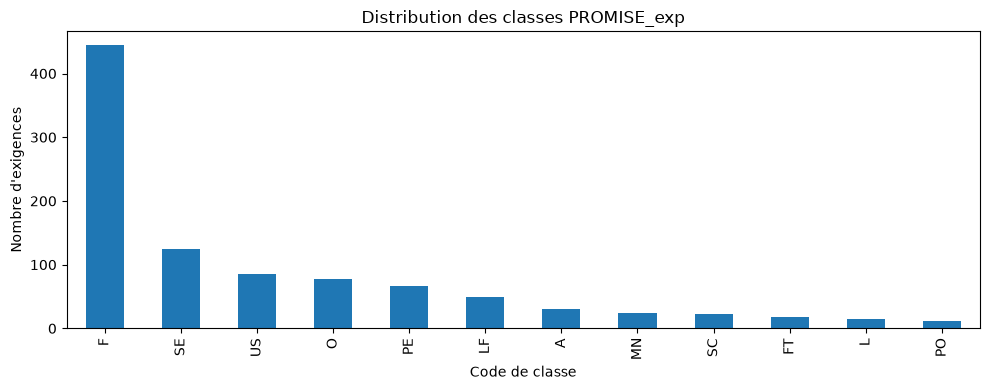

,Effectif
type_binaire,
Non fonctionnelle,525
Fonctionnelle,444


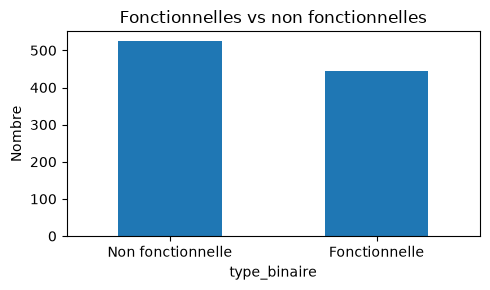

In [10]:
counts = df[class_col].value_counts(dropna=False)
display(pd.DataFrame({"Effectif":counts,"Pourcentage":(100*counts/len(df)).round(2)}))
plt.figure(figsize=(10,4));counts.plot(kind="bar");plt.title("Distribution des classes PROMISE_exp");plt.ylabel("Nombre d'exigences");plt.xlabel("Code de classe");plt.tight_layout();plt.savefig("01_distribution_classes.png",dpi=150);plt.show()
# Classe F = fonctionnelle ; les autres codes = non fonctionnelle
df["type_binaire"] = np.where(df[class_col].astype(str).str.strip().str.upper().eq("F"),"Fonctionnelle","Non fonctionnelle")
binary = df["type_binaire"].value_counts()
display(binary.to_frame("Effectif"))
plt.figure(figsize=(5,3));binary.plot(kind="bar");plt.ylabel("Nombre");plt.title("Fonctionnelles vs non fonctionnelles");plt.xticks(rotation=0);plt.tight_layout();plt.savefig("02_distribution_binaire.png",dpi=150);plt.show()

## 4. Longueur des exigences

,longueur_mots,longueur_caracteres
count,969.0,969.0
mean,17.9,109.2
std,9.9,61.1
min,4.0,28.0
25%,11.0,70.0
50%,15.0,94.0
75%,21.0,128.0
max,86.0,546.0


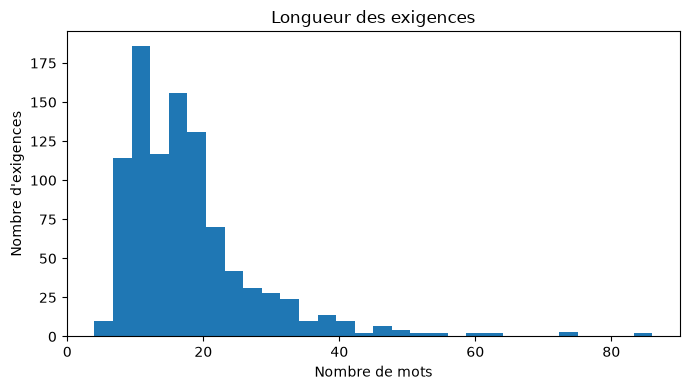

In [11]:
df["longueur_mots"] = df[text_col].fillna("").astype(str).str.split().str.len()
df["longueur_caracteres"] = df[text_col].fillna("").astype(str).str.len()
display(df[["longueur_mots","longueur_caracteres"]].describe().round(1))
plt.figure(figsize=(7,4));plt.hist(df["longueur_mots"],bins=30);plt.xlabel("Nombre de mots");plt.ylabel("Nombre d'exigences");plt.title("Longueur des exigences");plt.tight_layout();plt.savefig("03_longueurs.png",dpi=150);plt.show()

## 5. Cinq exemples et cas difficiles

In [12]:
# Trois exemples réels du corpus (échantillonnage déterministe)
examples = df[[text_col,class_col]].sample(n=min(5,len(df)),random_state=42)
display(examples.rename(columns={text_col:"Texte",class_col:"Classe d'origine"}))
print("Exigence la plus longue :")
display(df.nlargest(1,"longueur_mots")[[text_col,class_col,"longueur_mots"]])
print("Exigence la plus courte :")
display(df.nsmallest(1,"longueur_mots")[[text_col,class_col,"longueur_mots"]])

,Texte,Classe d'origine
575,The product shall have audit capabilities.The ...,SE
259,The recycled parts search results provided to ...,F
388,Users should be able to access their streaming...,US
495,The product shall be available 24 hours per da...,A
70,The system shall help the user avoid making mi...,US


Exigence la plus longue :


,RequirementText,_class_,longueur_mots
968,The website must provide highest degree of sec...,SE,86


Exigence la plus courte :


,RequirementText,_class_,longueur_mots
827,Customized information is displayed.,F,4


**Exemples construits — ne proviennent PAS du corpus :**

1. *The application should respond quickly.* → Non fonctionnelle ; **difficile** car « quickly » n'a pas de seuil mesurable.
2. *Administrators can delete accounts, but accounts must never be deleted.* → Deux exigences potentiellement **contradictoires** ; une revue humaine est nécessaire.

Ces exemples servent à préciser les besoins du projet, et **ne sont pas des résultats de modèles**.

## 6. Prétraitement minimal et comparaison avant / après

In [13]:
import re

def clean_minimal(text):
    # Préserver les négations, chiffres, symboles utiles, ponctuation et casse pour audit
    text = str(text)
    return re.sub(r"\s+", " ", text).strip()

compare = df[[text_col]].head(5).copy()
compare["apres"] = compare[text_col].map(clean_minimal)
compare.columns=["avant","apres"]
display(compare)
print("Textes modifiés :",int((df[text_col].fillna("").astype(str) != df[text_col].fillna("").astype(str).map(clean_minimal)).sum()))

,avant,apres
0,The system shall refresh the display every 60 ...,The system shall refresh the display every 60 ...
1,The application shall match the color of the s...,The application shall match the color of the s...
2,If projected the data must be readable. On a...,If projected the data must be readable. On a 1...
3,The product shall be available during normal b...,The product shall be available during normal b...
4,If projected the data must be understandable....,If projected the data must be understandable. ...


Textes modifiés : 189


### Décisions justifiées
- **Casse :** conservée dans le texte de référence ; normalisation éventuelle uniquement pour une baseline.
- **Nombres/dates :** conservés (contraintes quantitatives critiques).
- **Négation :** conservée (*not*, *never*, *no*) pour ne pas inverser le sens.
- **Ponctuation :** conservée dans le texte de référence ; peut séparer des propositions.
- **Étiquettes et ProjectID :** conservés séparément de la colonne texte pour éviter les fuites d'information.

**Risque identifié :** trop nettoyer le texte peut supprimer des contraintes et empêcher la détection de contradictions.

## 7. Export et synthèse automatique

In [ ]:
from collections import Counter
summary = f"""# Rapport court — Exploration PROMISE_exp

- Nombre d'exigences : **{len(df)}**.
- Nombre de colonnes initiales : **{len(df.columns)-3}** (les colonnes calculées sont exclues ; vérifier en cas de changement de schéma).
- Valeurs manquantes (texte) : **{df[text_col].isna().sum()}**.
- Textes dupliqués : **{df[text_col].duplicated().sum()}**.
- Fonctionnelles : **{(df['type_binaire']=='Fonctionnelle').sum()}**.
- Non fonctionnelles : **{(df['type_binaire']=='Non fonctionnelle').sum()}**.
- Longueur médiane : **{df['longueur_mots'].median():.0f} mots**.
- Classe la moins fréquente : **{counts.idxmin()} ({counts.min()} exemples)**.

## Analyse
Corpus annoté utile pour la classification fonctionnelle / non fonctionnelle.
Les classes sont déséquilibrées : utiliser macro-F1 et un découpage par projet si possible.
Ce corpus n'annotant pas directement l'ambiguïté ou la contradiction, ces tâches demandent des données annotées séparément.

## Prétraitement
Nettoyage prudent des espaces, conservation des négations, nombres et textes originaux.

## Suite
Préparer une séparation entraînement/validation/test sans fuite et comparer les baselines TF-IDF et embeddings.

**Aucun modèle n'a été entraîné dans cette exploration.**
"""
Path("Rapport_Exploration_ReqMind.md").write_text(summary,encoding="utf-8")
df.to_csv("PROMISE_exp_exploration.csv",index=False)
print(summary)

# Rapport court — Exploration PROMISE_exp

- Nombre d'exigences : **969**.
- Nombre de colonnes initiales : **3** (les colonnes calculées sont exclues ; vérifier en cas de changement de schéma).
- Valeurs manquantes (texte) : **0**.
- Textes dupliqués : **0**.
- Fonctionnelles : **444**.
- Non fonctionnelles : **525**.
- Longueur médiane : **15 mots**.
- Classe la moins fréquente : **PO (12 exemples)**.

## Analyse
Corpus annoté utile pour la classification fonctionnelle / non fonctionnelle.
Les classes sont déséquilibrées : utiliser macro-F1 et un découpage par projet si possible.
Ce corpus n'annotant pas directement l'ambiguïté ou la contradiction, ces tâches demandent des données annotées séparément.

## Prétraitement
Nettoyage prudent des espaces, conservation des négations, nombres et textes originaux.

## Suite
Préparer une séparation entraînement/validation/test sans fuite et comparer les baselines TF-IDF et embeddings.

**Aucun modèle n'a été entraîné dans cette exploration.**
